# **Layer-wise feature trajectory analysis with DinoV3**
The goal of this notebook is to determine and visualize how the [CLS] tokens for different classes, such as 'Cat' and 'Dog', correlate and relate to one another after each attention block

## **1. Importing**

In [ ]:
import time
import random
import requests
from io import BytesIO
from functools import partial

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from PIL import Image

import torchvision
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import DataLoader

from transformers import AutoImageProcessor, AutoModel
from huggingface_hub import login
from sklearn.decomposition import PCA
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### **1.1 Hugging Face**

In [3]:
from huggingface_hub import login
login()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
model_name = "facebook/dinov3-vit7b16-pretrain-lvd1689m"

print(f"Loading flagship model: {model_name}")
print(f"Targeting Architecture: 40 Layers, 4096 Embedding Dim")

if 'dtype' not in locals():
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32

try:
    model = AutoModel.from_pretrained(
        model_name,
        torch_dtype=dtype,
        low_cpu_mem_usage=True,
        attn_implementation="eager"
    ).to(device).eval()

    processor = AutoImageProcessor.from_pretrained(model_name)

    num_registers = getattr(model.config, "num_register_tokens", 4)
    print(f"Model loaded. Number of register tokens identified: {num_registers}")

    transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

    if hasattr(model, "vision_model"):
        num_layers = len(model.vision_model.encoder.layers)
    else:
        num_layers = len(model.layer)

    print(f"Success! Model loaded with {num_layers} layers.")

except Exception as e:
    print(f"Error loading model: {e}")
    print("Tip: If you run out of memory (OOM), try 'dinov3-vitl16' (Large, 24 layers) instead.")

Loading flagship model: facebook/dinov3-vit7b16-pretrain-lvd1689m
Targeting Architecture: 40 Layers, 4096 Embedding Dim


config.json:   0%|          | 0.00/746 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/48.7k [00:00<?, ?B/s]

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/687 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

Model loaded. Number of register tokens identified: 4
Success! Model loaded with 40 layers.


## **2. Data**

### **2.1 CIFAR-10/CIFAR-100**

In [6]:
dataset_cifar10 = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
loader_cifar10 = DataLoader(dataset_cifar10, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR10 samples (OOD - CIFAR-10): {len(dataset_cifar10)}")

100%|██████████| 170M/170M [00:14<00:00, 11.8MB/s]


Amount of CIFAR10 samples (OOD - CIFAR-10): 10000


In [7]:
dataset_cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
loader_cifar100 = DataLoader(dataset_cifar100, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR100 samples (OOD - CIFAR-100): {len(dataset_cifar100)}")

100%|██████████| 169M/169M [00:19<00:00, 8.51MB/s]


Amount of CIFAR100 samples (OOD - CIFAR-100): 10000


### **2.2 Oxford-IIIT Pet**
Oxford-IIIT Pet provides hierarchical labels such as: Species: *Cat/Dog -> Breed: Persian/Beagle*.
This is crucial for our testing if the model seperates *species* in early layers and *breeds* in later layers

In [9]:
dataset_pets = OxfordIIITPet(root='./data', split='test', download=True, transform=transform)
loader_pets = DataLoader(dataset_pets, batch_size=64, shuffle=False, num_workers=2)

print(f"Amount of OxfordIIITPet samples: {len(dataset_pets)}")

100%|██████████| 792M/792M [00:35<00:00, 22.5MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.8MB/s]


Amount of OxfordIIITPet samples: 3669


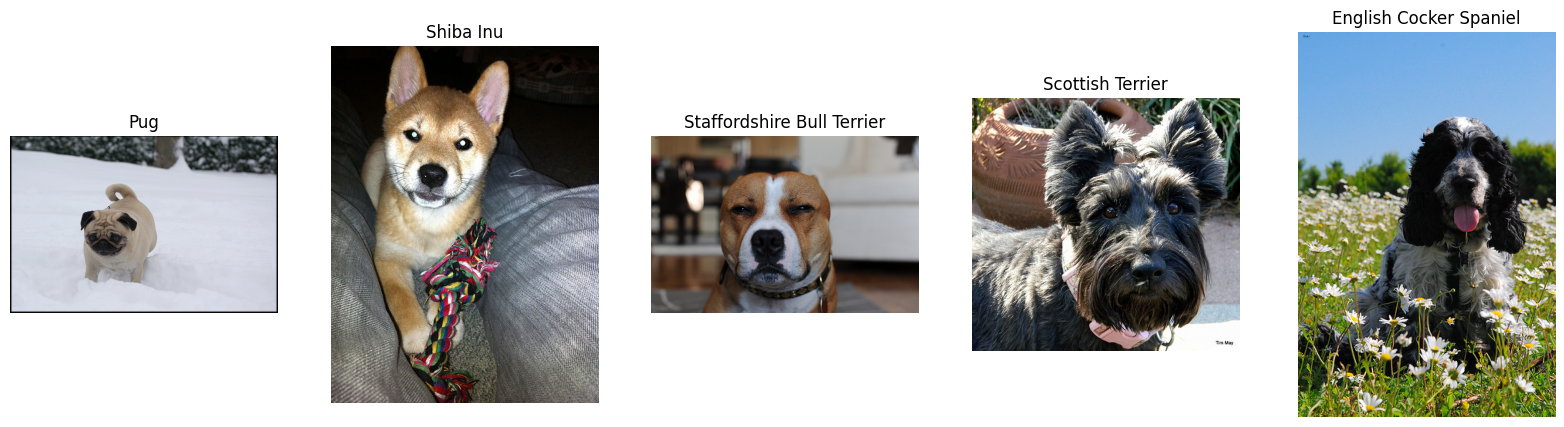

In [10]:
vis_dataset = OxfordIIITPet(root='./data', split='test', download=True, transform=None)

class_names = vis_dataset.classes

random_indices = random.sample(range(len(vis_dataset)), 5)
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, idx in zip(axes, random_indices):
    img, target = vis_dataset[idx]

    predicted_name = class_names[target]

    ax.imshow(img)
    ax.set_title(predicted_name)
    ax.axis('off')

plt.show()

### **2.3 High Resolution images**
Since Oxford-IIIT Pet image dataset is in HD quality it might be enough to conduct our experiment. For our purposes we will try to import high-resolution images as well.

In [11]:
image_urls = {
    "cat_1": "https://upload.wikimedia.org/wikipedia/commons/thumb/b/b6/Felis_catus-cat_on_snow.jpg/640px-Felis_catus-cat_on_snow.jpg",
    "cat_2": "https://upload.wikimedia.org/wikipedia/commons/thumb/4/4d/Cat_November_2010-1a.jpg/1024px-Cat_November_2010-1a.jpg",
    "cat_3": "https://upload.wikimedia.org/wikipedia/commons/thumb/4/47/Scottish-Fold.jpg/640px-Scottish-Fold.jpg",
    "dog_1": "https://upload.wikimedia.org/wikipedia/commons/thumb/7/77/Shiba_Inu_red.jpg/640px-Shiba_Inu_red.jpg",
    "dog_2": "https://upload.wikimedia.org/wikipedia/commons/thumb/4/4b/Siberian-husky-1291343_1920.jpg/640px-Siberian-husky-1291343_1920.jpg",
    "dog_3": "https://upload.wikimedia.org/wikipedia/commons/thumb/c/c8/Pug_dog.JPG/640px-Pug_dog.JPG"
}

Failed to load cat_1: 429 Client Error: Use thumbnail steps listed on https://w.wiki/GHai. Please contact noc@wikimedia.org for further information (a765913) for url: https://upload.wikimedia.org/wikipedia/commons/thumb/b/b6/Felis_catus-cat_on_snow.jpg/640px-Felis_catus-cat_on_snow.jpg
Status Code: 429
Response snippet: <!DOCTYPE html>
<html lang="en">
<meta charset="utf-8">
<title>Wikimedia Error</title>
<style>
* { margin: 0; padding: 0; }
body { background: #fff; f...
Failed to load cat_2: 429 Client Error: Use thumbnail steps listed on https://w.wiki/GHai. Please contact noc@wikimedia.org for further information (a765913) for url: https://upload.wikimedia.org/wikipedia/commons/thumb/4/4d/Cat_November_2010-1a.jpg/1024px-Cat_November_2010-1a.jpg
Status Code: 429
Response snippet: <!DOCTYPE html>
<html lang="en">
<meta charset="utf-8">
<title>Wikimedia Error</title>
<style>
* { margin: 0; padding: 0; }
body { background: #fff; f...
Failed to load cat_3: 429 Client Error: Use thumbnail

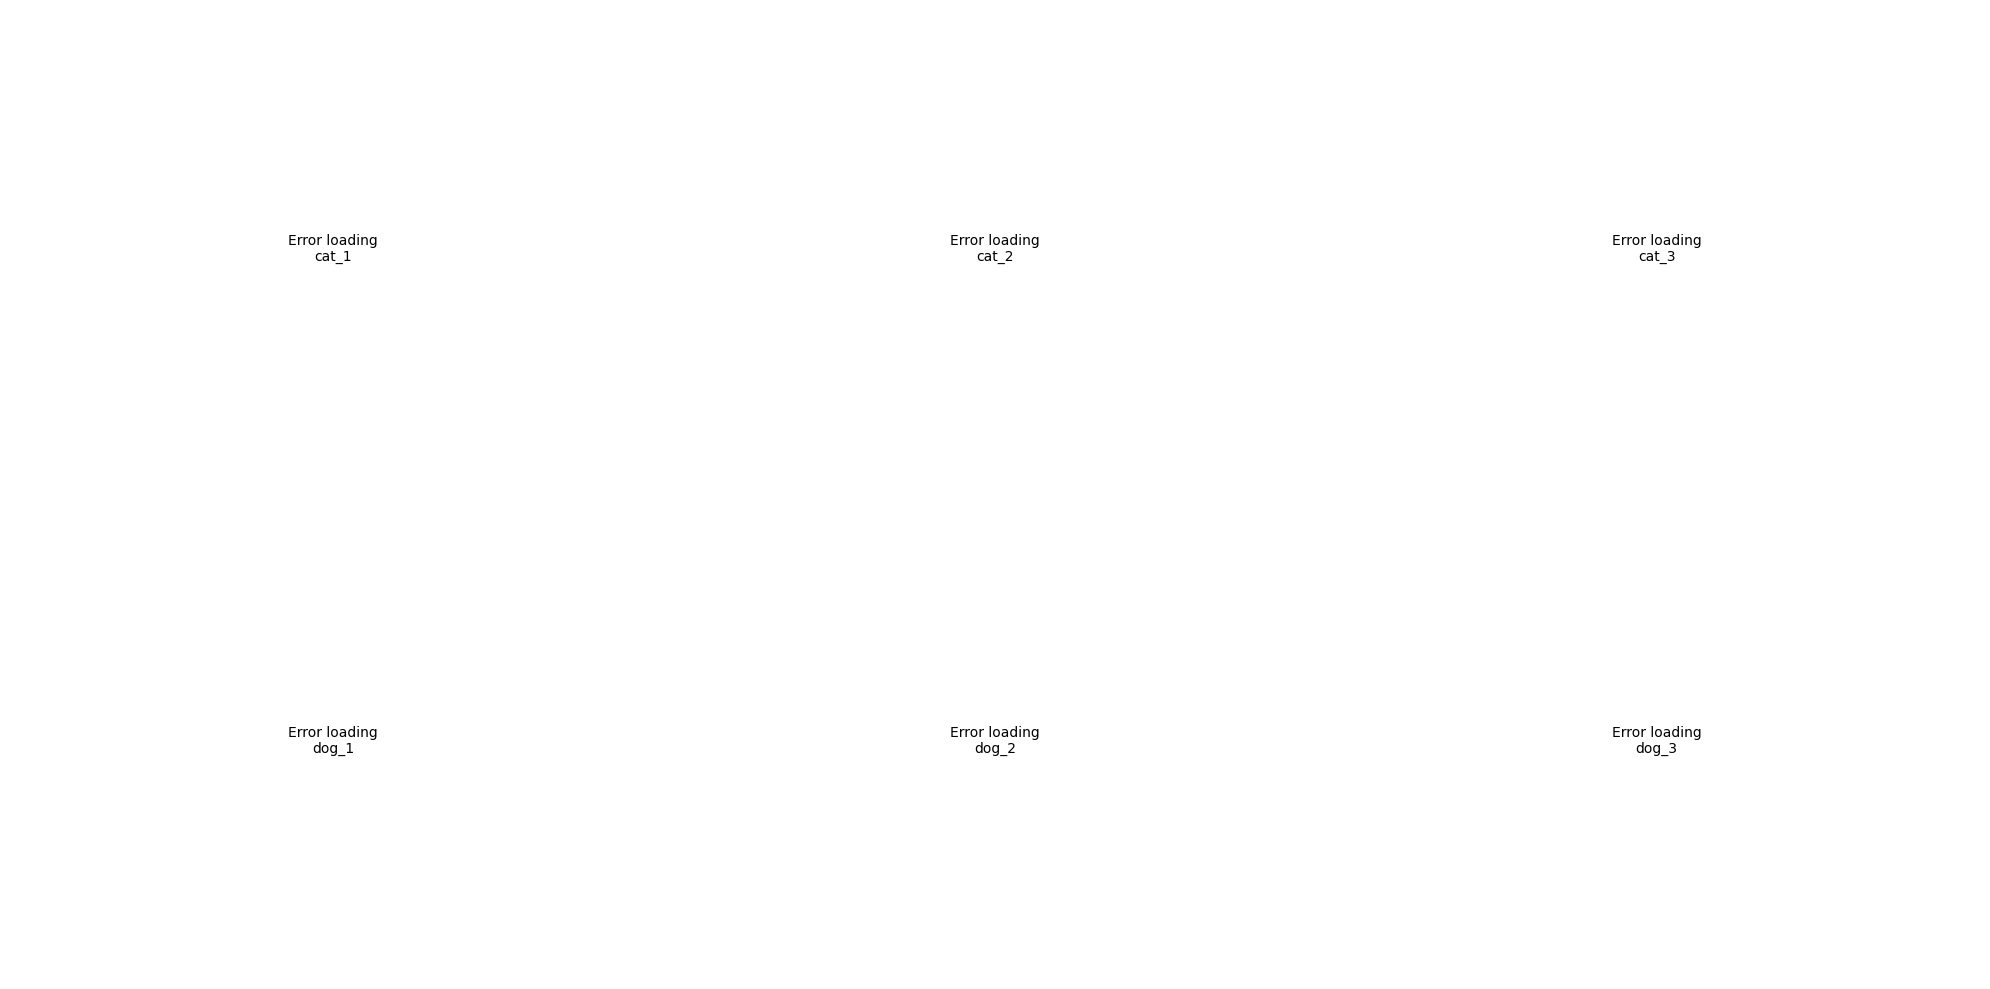

In [ ]:
num_cols = len(image_urls) // 2
fig, axes = plt.subplots(2, num_cols, figsize=(20, 10))
axes = axes.flatten()

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
    'Referer': 'https://www.wikipedia.org/'
}

for ax, (name, url) in zip(axes, image_urls.items()):
    try:
        response = requests.get(url, headers=headers, timeout=10)
        response.raise_for_status()

        img = Image.open(BytesIO(response.content))
        ax.imshow(img)
        ax.set_title(name)
        ax.axis('off')
    except Exception as e:
        print(f"Failed to load {name}: {e}")
        if 'response' in locals():
            print(f"Status Code: {response.status_code}")
            print(f"Response snippet: {response.text[:150]}...")
        ax.text(0.5, 0.5, f"Error loading\n{name}", ha='center', va='center')
        ax.axis('off')

plt.tight_layout()
plt.show()

## **3. DinoV3 Architecture**
At its core, DinoV3 is a **Vision Transformer (ViT)**. It is a massive stack of processing layers that takes an image, chops it into pieces, and learns how those pieces relate to each other.




### **3.1 Input patches**
Before the model does any thinking, it takes our image and cuts it into a grid of small squares called patches
*   **Patch Size**: 16x16 pixels
*   This turns a large picture into a sequence of small "tokens," similar to how a
language model processes a sentence word-by-word.


### **3.2 Layers**
The model is very deep. It consists of a stack of identical "building blocks" that process the information sequentially.
*   **Number of Layers**: There are **40 blocks** stacked on top of each other
*   **Embedding Dimension**: As the image data moves through these 40 layers, it is represented by a very wide vector of numbers. The "width" of this information highway is **4096 dimensions**.

### **3.3 Inside Each Layer**
*   **Attention block**: Each attention block in DinoV3 uses **32 attention heads**
*   **Multi-Layer Perceptron**: DinoV3 uses a modern, efficient version of an MLP called SwiGLU. The hidden dimension inside this MLP is massive—8192 —allowing it to store a vast amount of knowledge about visual concepts.


### **3.4 Special Features**
As a modern model DinoV3 includes few tricks.
*   **Register Token**: he model adds **4 extra "blank"** tokens to the input. Sometimes an image has "junk" data or background noise. These registers act like a trash bin, giving the model a place to store useless information so it doesn't clutter up the important features (like your Cat or Dog).
*   **Rotary Positional Embeddings (RoPE)**: Since the model chops the image into pieces, it needs to know where each piece goes (top-left, bottom-right, etc.). DinoV3 uses a system called axial RoPE to mathematically encode this location data, helping the model understand shapes and distances better



## **4. Acquiring activations**


### **4.1 Implementation**

In [13]:
activations = {}

In [14]:
def get_activation(name):
  """
  Gets an activation function for a specific layer in the model.

  :param name: The name of the layer to get the activation function for.
  """
  def hook(model, input, output):
    if isinstance(output, tuple):
      activations[name] = output[0].detach().cpu()
    else:
      activations[name] = output.detach().cpu()
  return hook

In [ ]:
if hasattr(model, "encoder") and hasattr(model.encoder, "layer"):
    layers = model.encoder.layer
elif hasattr(model, "blocks"):
    layers = model.blocks
elif hasattr(model, "layers"):
    layers = model.layers
elif hasattr(model, "layer"):
    layers = model.layer
else:
    print(model)
    raise AttributeError("Could not automatically locate the transformer blocks. See model structure above.")

for i, layer in enumerate(layers):
    layer_name = f"block_{i}"
    layer.register_forward_hook(get_activation(layer_name))

### **4.2 High resolution images**


In [ ]:
retry_strategy = Retry(
    total=5,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["HEAD", "GET", "OPTIONS"],
    backoff_factor=1
)

adapter = HTTPAdapter(max_retries=retry_strategy)
session = requests.Session()
session.mount("https://", adapter)
session.mount("http://", adapter)

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/114.0.0.0 Safari/537.36 BachelorsThesisBot/1.1',
    'Accept': 'image/avif,image/webp,image/apng,image/svg+xml,image/*,*/*;q=0.8',
    'Accept-Language': 'en-US,en;q=0.9',
    'Referer': 'https://commons.wikimedia.org/'
}

print("Downloading and transforming images...")

batch_high_images = []
batch_high_labels = []

for name, url in image_urls.items():
    try:
        original_url = url
        if "/thumb/" in original_url:
            parts = original_url.split('/')
            original_url = '/'.join([p for p in parts[:-1] if p != 'thumb'])

        response = session.get(original_url, headers=headers, timeout=15)
        response.raise_for_status()

        img = Image.open(BytesIO(response.content)).convert("RGB")

        img_tensor = transform(img)
        batch_high_images.append(img_tensor)
        batch_high_labels.append(name)

        print(f"Downloaded and transformed {name}")

        time.sleep(2)

    except Exception as e:
        print(f"Failed to download and transform {name}: {e}")

if batch_high_images:
    input_batch = torch.stack(batch_high_images).to(device)

    print(f"Running inference on batch of shape: {input_batch.shape}")
    with torch.no_grad():
        _ = model(pixel_values=input_batch)

    animal_trajectories = {name: {} for name in batch_high_labels}
else:
    print("No images were successfully loaded. Please check the URLs or your connection.")

Downloaded and transformed cat_1
Downloaded and transformed cat_2
Downloaded and transformed cat_3
Downloaded and transformed dog_1
Downloaded and transformed dog_2
Downloaded and transformed dog_3
Running inference on batch of shape: torch.Size([6, 3, 224, 224])


In [32]:
spatial_activations = {}

In [33]:
for layer_name, layer_tensor in activations.items():
    for batch_idx, animal_name in enumerate(batch_high_labels):

      cls_vector = layer_tensor[batch_idx, 0, :]
      animal_trajectories[animal_name][layer_name] = cls_vector

print("\nExtraction complete.")

last_layer = list(activations.keys())[-1]

print(f"Example: 'cat_1' at '{last_layer}' has vector shape: {animal_trajectories['cat_1'][last_layer].shape}")


Extraction complete.
Example: 'cat_1' at 'block_39' has vector shape: torch.Size([4096])


In [ ]:
print(f"Main keys (Animals): {list(animal_trajectories.keys())}")

first_animal = list(animal_trajectories.keys())[0]
print(f"\nLayers for '{first_animal}': {list(animal_trajectories[first_animal].keys())[:5]} ... (showing first 5)")

layer_0 = animal_trajectories[first_animal]['block_0']
print(f"\nVector at block_0 for '{first_animal}':\n Shape: {layer_0.shape}\n First 5 values: {layer_0[:5]}")

Main keys (Animals): ['cat_1', 'cat_2', 'cat_3', 'dog_1', 'dog_2', 'dog_3']

Layers for 'cat_1': ['block_0', 'block_1', 'block_2', 'block_3', 'block_4'] ... (showing first 5)

Vector at block_0 for 'cat_1':
 Shape: torch.Size([4096])
 First 5 values: tensor([ 0.0032, -0.0171, -0.0091,  0.0247,  0.0137], dtype=torch.float16)


## **Visualisation**

### **Cosine similiarity**
**Cosine similarity** is a metric used to measure how similar two vectors are irrespective of their size (magnitude). Mathematically, it measures the cosine of the angle between two vectors projected in a multi-dimensional space.

**The Geometric Intuition**
*   **Direction**: Represents the semantic content (e.g., "Feline characteristics")
*   **Magnitude (Length)**: Represents the strength or confidence of that feature (or sometimes image brightness/contrast).

Cosine similarity ignores the length and focuses strictly on the direction.

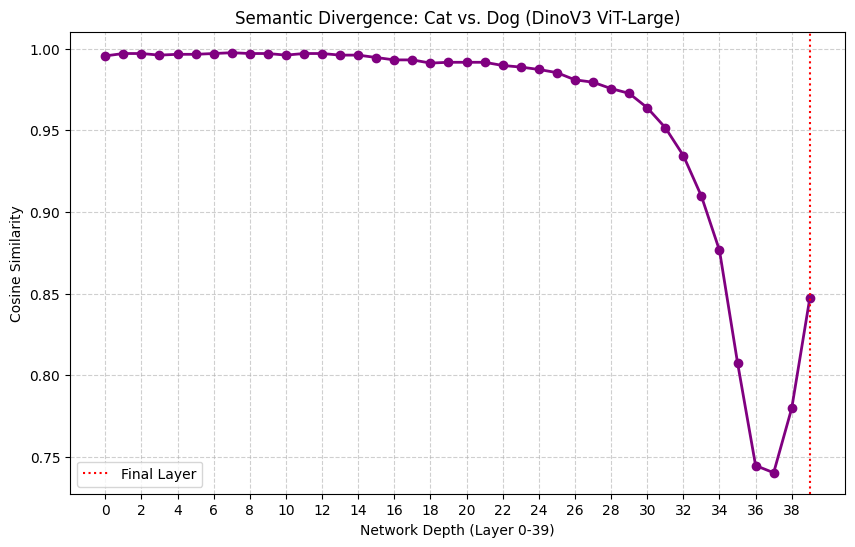

In [ ]:
if 'num_layers' not in locals():
    num_layers = len(activations.keys())
    print(f"Detected {num_layers} layers from activations.")

layers = [f"block_{i}" for i in range(num_layers)]

similarities = []

for layer in layers:
    cat_vecs = torch.stack([animal_trajectories[c][layer] for c in cats])
    dog_vecs = torch.stack([animal_trajectories[d][layer] for d in dogs])

    cat_centroid = torch.mean(cat_vecs, dim=0).unsqueeze(0)
    dog_centroid = torch.mean(dog_vecs, dim=0).unsqueeze(0)

    sim = F.cosine_similarity(cat_centroid, dog_centroid).item()
    similarities.append(sim)

plt.figure(figsize=(10, 6))

plt.plot(range(num_layers), similarities, marker='o', linewidth=2, color='purple')

plt.title(f"Semantic Divergence: Cat vs. Dog (DinoV3 ViT-Large)")
plt.xlabel(f"Network Depth (Layer 0-{num_layers-1})")
plt.ylabel("Cosine Similarity")
plt.grid(True, linestyle='--', alpha=0.6)

plt.xticks(range(0, num_layers, 2))

plt.axvline(x=num_layers-1, color='red', linestyle=':', label='Final Layer')

plt.legend()
plt.show()

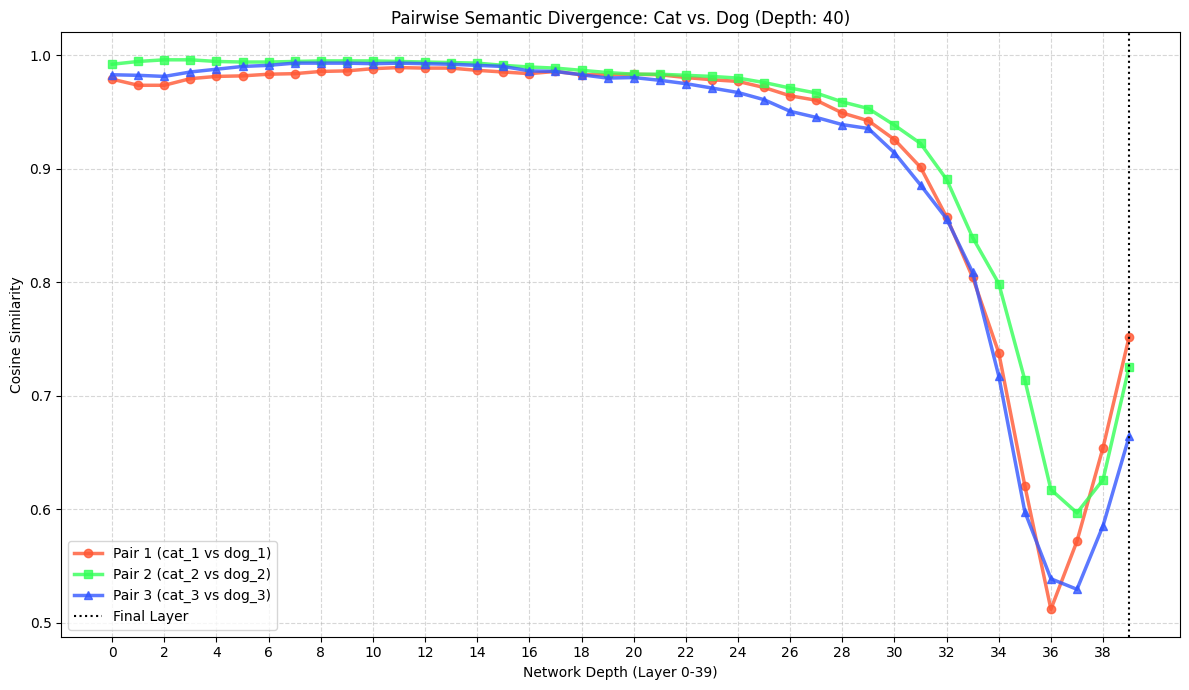

In [36]:
layers = [f"block_{i}" for i in range(num_layers)]
cats = ["cat_1", "cat_2", "cat_3"]
dogs = ["dog_1", "dog_2", "dog_3"]

pairwise_trajectories = {f"Pair {i+1} ({c} vs {d})": [] for i, (c, d) in enumerate(zip(cats, dogs))}

for layer in layers:
    for i, (cat_name, dog_name) in enumerate(zip(cats, dogs)):
        cat_vec = animal_trajectories[cat_name][layer].unsqueeze(0)
        dog_vec = animal_trajectories[dog_name][layer].unsqueeze(0)

        sim = F.cosine_similarity(cat_vec, dog_vec).item()

        key = f"Pair {i+1} ({cat_name} vs {dog_name})"
        pairwise_trajectories[key].append(sim)

plt.figure(figsize=(12, 7))

colors = ['#FF5733', '#33FF57', '#3357FF']
markers = ['o', 's', '^']

for idx, (label, sims) in enumerate(pairwise_trajectories.items()):
    plt.plot(range(num_layers), sims,
             marker=markers[idx % len(markers)],
             linewidth=2.5,
             color=colors[idx % len(colors)],
             label=label,
             alpha=0.8)

plt.title(f"Pairwise Semantic Divergence: Cat vs. Dog (Depth: {num_layers})")
plt.xlabel(f"Network Depth (Layer 0-{num_layers-1})")
plt.ylabel("Cosine Similarity")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(0, num_layers, 2))
plt.axvline(x=num_layers-1, color='black', linestyle=':', label='Final Layer')
plt.legend()
plt.tight_layout()
plt.show()

### **Cat vs Car**

In [ ]:
comparison_urls = {
    "Cat": "https://upload.wikimedia.org/wikipedia/commons/thumb/4/4d/Cat_November_2010-1a.jpg/1024px-Cat_November_2010-1a.jpg",
    "Car": "https://upload.wikimedia.org/wikipedia/commons/thumb/c/c6/2013_Porsche_911_Carrera_4S_%28991%29_%289626546987%29.jpg/640px-2013_Porsche_911_Carrera_4S_%28991%29_%289626546987%29.jpg"
}

activations = {}

batch_tensors = []
names = []

if 'headers' not in locals():
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
        'Referer': 'https://www.wikipedia.org/'
    }

print("Loading images...")
for name, url in comparison_urls.items():
    response = requests.get(url, headers=headers)
    response.raise_for_status()
    img = Image.open(BytesIO(response.content)).convert("RGB")
    batch_tensors.append(transform(img))
    names.append(name)

batch = torch.stack(batch_tensors).to(device)

print("Running inference...")
with torch.no_grad():
    _ = model(pixel_values=batch)

current_num_layers = len(activations)
layers = [f"block_{i}" for i in range(current_num_layers)]

cos_sims = []
pearson_corrs = []

def pearson(v1, v2):
    v1_c = v1 - v1.mean()
    v2_c = v2 - v2.mean()
    return F.cosine_similarity(v1_c.unsqueeze(0), v2_c.unsqueeze(0)).item()

for layer in layers:
    cat_vec = activations[layer][0, 0, :]
    car_vec = activations[layer][1, 0, :]

    cos_sims.append(F.cosine_similarity(cat_vec.unsqueeze(0), car_vec.unsqueeze(0)).item())
    pearson_corrs.append(pearson(cat_vec, car_vec))

plt.figure(figsize=(12, 6))

plt.plot(range(current_num_layers), cos_sims, marker='o', linewidth=2.5, color='#2ca02c', label='Cosine Similarity')

plt.plot(range(current_num_layers), pearson_corrs, marker='s', linewidth=2.5, color='#d62728', linestyle='--', label='Pearson Correlation')

plt.title(f"Feature Divergence: Cat (Biological) vs. Car (Mechanical) - {current_num_layers} Layers")
plt.xlabel(f"Network Depth (Layer 0-{current_num_layers-1})")
plt.ylabel("Similarity Score")
plt.axhline(y=0, color='black', linewidth=1, linestyle='-')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(0, current_num_layers, 2))
plt.legend()
plt.show()

Loading images...


HTTPError: 429 Client Error: Use thumbnail steps listed on https://w.wiki/GHai. Please contact noc@wikimedia.org for further information (a765913) for url: https://upload.wikimedia.org/wikipedia/commons/thumb/4/4d/Cat_November_2010-1a.jpg/1024px-Cat_November_2010-1a.jpg

In [ ]:
comparison_urls = {
    "Cat": "https://upload.wikimedia.org/wikipedia/commons/thumb/4/4d/Cat_November_2010-1a.jpg/1024px-Cat_November_2010-1a.jpg",
    "Phone": "https://upload.wikimedia.org/wikipedia/commons/thumb/6/66/Telephone_modele_U43-MGR_Lyon-IMG_9923.jpg/640px-Telephone_modele_U43-MGR_Lyon-IMG_9923.jpg"
}

activations = {}

batch_tensors = []
names = []

if 'headers' not in locals():
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
        'Referer': 'https://www.wikipedia.org/'
    }

print("Loading images...")
for name, url in comparison_urls.items():
    response = requests.get(url, headers=headers)
    response.raise_for_status()
    img = Image.open(BytesIO(response.content)).convert("RGB")
    batch_tensors.append(transform(img))
    names.append(name)

batch = torch.stack(batch_tensors).to(device)

print("Running inference...")
with torch.no_grad():
    _ = model(pixel_values=batch)

current_num_layers = len(activations)
layers = [f"block_{i}" for i in range(current_num_layers)]

cos_sims = []
pearson_corrs = []

def pearson(v1, v2):
    v1_c = v1 - v1.mean()
    v2_c = v2 - v2.mean()
    return F.cosine_similarity(v1_c.unsqueeze(0), v2_c.unsqueeze(0)).item()

for layer in layers:
    cat_vec = activations[layer][0, 0, :]
    car_vec = activations[layer][1, 0, :]

    cos_sims.append(F.cosine_similarity(cat_vec.unsqueeze(0), car_vec.unsqueeze(0)).item())
    pearson_corrs.append(pearson(cat_vec, car_vec))

plt.figure(figsize=(12, 6))

plt.plot(range(current_num_layers), cos_sims, marker='o', linewidth=2.5, color='#2ca02c', label='Cosine Similarity')

plt.plot(range(current_num_layers), pearson_corrs, marker='s', linewidth=2.5, color='#d62728', linestyle='--', label='Pearson Correlation')

plt.title(f"Feature Divergence: Cat (Biological) vs. Phone (Mechanical) - {current_num_layers} Layers")
plt.xlabel(f"Network Depth (Layer 0-{current_num_layers-1})")
plt.ylabel("Similarity Score")
plt.axhline(y=0, color='black', linewidth=1, linestyle='-')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(0, current_num_layers, 2))
plt.legend()
plt.show()

## **Pearson Correlation**
The Pearson correlation coefficient is a statistical metric that measures the strength and direction of the linear relationship between two continuous variables (or vectors).

Unlike Cosine Similarity, which measures the angle from the origin, Pearson Correlation centers the data by subtracting the mean of each vector before measuring alignment. This means it focuses purely on the pattern of variation (the shape of peaks and valleys) rather than the magnitude or absolute position of the values.

In [ ]:
def pearson_correlation(v1, v2):
    """
    Calculates Pearson correlation between two 1D tensors.
    Formula: Covariance(v1, v2) / (StdDev(v1) * StdDev(v2))
    """
    v1_centered = v1 - v1.mean()
    v2_centered = v2 - v2.mean()

    return torch.nn.functional.cosine_similarity(
        v1_centered.unsqueeze(0),
        v2_centered.unsqueeze(0)
    ).item()

layers = [f"block_{i}" for i in range(num_layers)]
cats = ["cat_1", "cat_2", "cat_3"]
dogs = ["dog_1", "dog_2", "dog_3"]

correlation_trajectories = {f"Pair {i+1} ({c} vs {d})": [] for i, (c, d) in enumerate(zip(cats, dogs))}

for layer in layers:
    for i, (cat_name, dog_name) in enumerate(zip(cats, dogs)):
        cat_vec = animal_trajectories[cat_name][layer]
        dog_vec = animal_trajectories[dog_name][layer]

        corr = pearson_correlation(cat_vec, dog_vec)

        key = f"Pair {i+1} ({cat_name} vs {dog_name})"
        correlation_trajectories[key].append(corr)

plt.figure(figsize=(12, 7))

colors = ['#FF5733', '#33FF57', '#3357FF']
markers = ['o', 's', '^']

for idx, (label, corrs) in enumerate(correlation_trajectories.items()):
    plt.plot(range(num_layers), corrs,
             marker=markers[idx % len(markers)],
             linewidth=2.5,
             color=colors[idx % len(colors)],
             label=label,
             alpha=0.8)

plt.title(f"Pairwise Feature Correlation: Cat vs. Dog ({num_layers} Layers)")
plt.xlabel(f"Network Depth (Layer 0-{num_layers-1})")
plt.ylabel("Pearson Correlation (1.0 = Linear, 0.0 = Uncorrelated)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(0, num_layers, 2))
plt.axvline(x=num_layers-1, color='black', linestyle=':', label='Final Layer')
plt.legend()
plt.tight_layout()
plt.show()

## **Brain Scan Gif**

In [38]:
scan_urls = {
    "cat_1": "https://upload.wikimedia.org/wikipedia/commons/thumb/b/b6/Felis_catus-cat_on_snow.jpg/640px-Felis_catus-cat_on_snow.jpg",
    "phone": "https://upload.wikimedia.org/wikipedia/commons/thumb/6/66/Telephone_modele_U43-MGR_Lyon-IMG_9923.jpg/640px-Telephone_modele_U43-MGR_Lyon-IMG_9923.jpg",
    "dog_1": "https://upload.wikimedia.org/wikipedia/commons/thumb/7/77/Shiba_Inu_red.jpg/640px-Shiba_Inu_red.jpg",
    "car_1": "https://upload.wikimedia.org/wikipedia/commons/thumb/c/c6/2013_Porsche_911_Carrera_4S_%28991%29_%289626546987%29.jpg/640px-2013_Porsche_911_Carrera_4S_%28991%29_%289626546987%29.jpg"
}

### **Global PCA**

In [ ]:
def generate_layerwise_gifs(model, image_urls, transform, device, pca_mode="global", mean_subtraction=False, softmax_scaling=False):
    """
    Runs inference on a set of images, captures layer-wise spatial features,
    fits a PCA, and generates a visualization GIF for each image.
    """
    activations = {}
    def save_activation(name, model, input, output):
        if isinstance(output, tuple):
            activations[name] = output[0].detach().cpu()
        else:
            activations[name] = output.detach().cpu()

    for module in model.modules():
        if hasattr(module, "_forward_hooks"):
            module._forward_hooks.clear()

    if hasattr(model, "layer"): blocks = model.layer
    elif hasattr(model, "encoder") and hasattr(model.encoder, "layer"): blocks = model.encoder.layer
    elif hasattr(model, "vision_model"): blocks = model.vision_model.encoder.layers
    else: raise ValueError("Could not locate Transformer blocks in model architecture.")

    num_layers = len(blocks)

    for i, layer in enumerate(blocks):
        layer.register_forward_hook(partial(save_activation, f"block_{i}"))

    batch_tensors = []
    valid_labels = []

    retry_strategy = Retry(total=5, status_forcelist=[429, 500, 502, 503, 504], backoff_factor=1)
    adapter = HTTPAdapter(max_retries=retry_strategy)
    session = requests.Session()
    session.mount("https://", adapter)
    session.mount("http://", adapter)

    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) Chrome/114.0.0.0 Safari/537.36 BachelorsBot/1.1',
        'Accept': 'image/avif,image/webp,*/*;q=0.8',
        'Referer': 'https://commons.wikimedia.org/'
    }

    for name, url in image_urls.items():
        try:
            original_url = url
            if "/thumb/" in original_url:
                parts = original_url.split('/')
                original_url = '/'.join([p for p in parts[:-1] if p != 'thumb'])

            response = session.get(original_url, headers=headers, timeout=15)
            response.raise_for_status()

            img = Image.open(BytesIO(response.content)).convert("RGB")
            batch_tensors.append(transform(img))
            valid_labels.append(name)
            time.sleep(1.5)
        except Exception as e:
            print(f"Failed {name}: {e}")

    if not batch_tensors:
        return []

    batch = torch.stack(batch_tensors).to(device)

    with torch.no_grad():
        _ = model(pixel_values=batch)

    all_spatial_data = []
    layer_means = {}

    if pca_mode == "global":
        for i in range(num_layers):
            layer_name = f"block_{i}"
            tensor = activations[layer_name]
            start_idx = 5 if tensor.shape[1] > 200 else 1
            patches = tensor[:, start_idx:, :]

            if mean_subtraction:
                layer_mean = patches.mean(dim=(0, 1), keepdim=True)
                layer_means[layer_name] = layer_mean
                patches = patches - layer_mean

            flat = patches.reshape(-1, patches.shape[-1])
            all_spatial_data.append(flat)

        global_data = torch.cat(all_spatial_data, dim=0)
        pca = PCA(n_components=3)
        pca.fit(global_data.numpy())

    generated_files = []

    for batch_idx, label in enumerate(valid_labels):
        image_layer_data = {}
        frames_data = []

        for i in range(num_layers):
            layer_name = f"block_{i}"
            tensor = activations[layer_name]
            start_idx = 5 if tensor.shape[1] > 200 else 1
            
            if pca_mode == "global":
                img_patches = tensor[batch_idx:batch_idx+1, start_idx:, :]
                if mean_subtraction:
                    layer_mean = layer_means[layer_name]
                    img_patches = img_patches - layer_mean
                data = img_patches.squeeze(0).numpy()
                
                rgb = pca.transform(data)
                
                if softmax_scaling:
                    scaled_rgb = 2.0 * rgb
                    e_x = np.exp(scaled_rgb - np.max(scaled_rgb, axis=-1, keepdims=True))
                    rgb = e_x / e_x.sum(axis=-1, keepdims=True)
                else:
                    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min())
                    
                frames_data.append(rgb)
            else:
                data = tensor[batch_idx, start_idx:, :].numpy()
                local_pca = PCA(n_components=3)
                rgb = local_pca.fit_transform(data)
                rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min())
                frames_data.append(rgb)

        fig, ax = plt.subplots(figsize=(5, 5))
        ax.axis('off')

        def update(frame):
            rgb_data = frames_data[frame]
            grid_side = int(np.sqrt(rgb_data.shape[0]))
            img_grid = rgb_data.reshape(grid_side, grid_side, 3)

            ax.clear()
            ax.axis('off')
            title_suffix = "Local PCA" if pca_mode == "local" else ("Softmax" if softmax_scaling else ("Mean-Subtracted" if mean_subtraction else "Global PCA"))
            ax.set_title(f"{label} ({title_suffix}) | Layer {frame}/{num_layers-1}")
            ax.imshow(img_grid, interpolation='nearest')

        anim = FuncAnimation(fig, update, frames=range(num_layers), interval=400)
        filename = f"dinov3_scan_{label}_{pca_mode}.gif"
        anim.save(filename, writer='pillow')
        generated_files.append(filename)
        plt.close(fig)

    return generated_files

In [ ]:
gif_files = generate_layerwise_gifs(model, scan_urls, transform, device, pca_mode="global")

try:
    from google.colab import files
    if gif_files:
        for f in gif_files: files.download(f)
except ImportError:
    pass

Step 1: Registering Hooks...
 > Found 40 layers.

Step 2: Loading Images...
 > Loaded: cat_1
 > Loaded: phone
 > Loaded: dog_1
 > Loaded: car_1

Step 3: Running Inference on batch torch.Size([4, 3, 224, 224])...

Step 4: fitting Global PCA for consistent colors...
 > PCA fit on 31360 vectors.

Step 5: Generating GIFs...
 > Processing cat_1...
 > Processing phone...
 > Processing dog_1...
 > Processing car_1...

Done! Generated 4 GIFs: ['dinov3_scan_cat_1.gif', 'dinov3_scan_phone.gif', 'dinov3_scan_dog_1.gif', 'dinov3_scan_car_1.gif']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Global PCA with mean substraction**

In [ ]:
gif_files_mean_sub = generate_layerwise_gifs(model, scan_urls, transform, device, pca_mode="global", mean_subtraction=True)

try:
    from google.colab import files
    if gif_files_mean_sub:
        for f in gif_files_mean_sub: files.download(f)
except ImportError:
    pass

Step 1: Registering Hooks...
 > Found 40 layers.

Step 2: Loading Images...
 > Loaded: cat_1
 > Loaded: phone
 > Loaded: dog_1
 > Loaded: car_1

Step 3: Running Inference on batch torch.Size([4, 3, 224, 224])...

Step 4: Fitting Global PCA with LAYER-WISE MEAN SUBTRACTION...
 > PCA fit on 31360 centered vectors.

Step 5: Generating Softmax-Enhanced GIFs...
 > Processing cat_1...
 > Processing phone...
 > Processing dog_1...
 > Processing car_1...

Done! Generated 4 GIFs: ['dinov3_scan_cat_1_softmax.gif', 'dinov3_scan_phone_softmax.gif', 'dinov3_scan_dog_1_softmax.gif', 'dinov3_scan_car_1_softmax.gif']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **Softmax and multiplying for Contrast**

In [ ]:
gif_files_softmax = generate_layerwise_gifs(model, scan_urls, transform, device, pca_mode="global", mean_subtraction=True, softmax_scaling=True)

try:
    from google.colab import files
    if gif_files_softmax:
        for f in gif_files_softmax: files.download(f)
except ImportError:
    pass

### **Local PCA**

In [ ]:
gif_local_pca_files = generate_layerwise_gifs(model, scan_urls, transform, device, pca_mode="local")

try:
    from google.colab import files
    if gif_local_pca_files:
        for f in gif_local_pca_files: files.download(f)
except ImportError:
    pass